# Audio classification: Barbie vs Puppy

Compare two convolutional classifiers using log-mel spectrograms and MFCC features. The WAV files used in the experiment are included in `dataset/barbie/` and `dataset/puppy/`. Install the libraries imported below, including librosa, audiomentations, PyTorch, and scikit-learn.

The split is at file level. If files are clips from the same original recording, the train and test sets can share a source, making the score optimistic; group by source when that information is available. The test set contains only 15 files in the saved run, so results have high uncertainty. Both models are compared on the same test set; an additional independent dataset would be needed to assess a model selected using those scores.

**Data:** The two-class WAV collection used here is included in `dataset/barbie/` and `dataset/puppy/`. Its original public source is not confirmed.

In [1]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import copy
import random

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f"Используется устройство: {device}")

~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Используется устройство: cpu


In [2]:
DATA_DIR = Path('./dataset')
SAMPLE_RATE = 22050
DURATION = 5
N_SAMPLES = SAMPLE_RATE * DURATION

BATCH_SIZE = 16
EPOCHS = 100
LEARNING_RATE = 0.0001
AUGMENTATION_MULTIPLIER = 8  # увелечение датасета за счет аугментаций

In [3]:
def load_audio_files(data_dir):
    audio_files = []
    labels = []

    barbie_dir = data_dir / 'barbie'
    if barbie_dir.exists():
        for audio_path in sorted(barbie_dir.glob('*.wav')):
            audio_files.append(str(audio_path))
            labels.append(0)

    puppy_dir = data_dir / 'puppy'
    if puppy_dir.exists():
        for audio_path in sorted(puppy_dir.glob('*.wav')):
            audio_files.append(str(audio_path))
            labels.append(1)
    
    df = pd.DataFrame({
        'file_path': audio_files,
        'label': labels,
        'class_name': ['barbie' if l == 0 else 'puppy' for l in labels]
    })
    
    return df

df = load_audio_files(DATA_DIR)
print(f"Всего аудио файлов: {len(df)}")
print(f"\nРаспределение по классам:")
print(df['class_name'].value_counts())
df.head()

Всего аудио файлов: 98

Распределение по классам:
class_name
barbie    50
puppy     48
Name: count, dtype: int64


,file_path,label,class_name
0,dataset/barbie/barbie_0.wav,0,barbie
1,dataset/barbie/barbie_1.wav,0,barbie
2,dataset/barbie/barbie_10.wav,0,barbie
3,dataset/barbie/barbie_11.wav,0,barbie
4,dataset/barbie/barbie_12.wav,0,barbie


## ИСПРАВЛЕННАЯ Аугментация данных

In [4]:
import audiomentations as A

augmentation_pipeline = A.Compose([
    # Изменение высоты тона
    A.PitchShift(min_semitones=-4, max_semitones=4, p=0.7),
    
    # Изменение скорости
    A.TimeStretch(min_rate=0.8, max_rate=1.25, p=0.7),
    
    # Добавление белого шума
    A.AddGaussianNoise(min_amplitude=0.001, max_amplitude=0.015, p=0.6),
    
    # Изменение громкости
    A.Gain(min_gain_db=-12, max_gain_db=12),

    A.Shift(min_shift=-0.3, max_shift=0.3),
    
    # Нормализация
    A.Normalize(p=0.5),
    
    # Полярная инверсия
    A.PolarityInversion(p=0.3),
    
    # Low pass filter
    A.LowPassFilter(min_cutoff_freq=1500, max_cutoff_freq=7000, p=0.4),
    
    # High pass filter
    A.HighPassFilter(min_cutoff_freq=20, max_cutoff_freq=2400, p=0.4),
    
    # Band pass filter
    A.BandPassFilter(min_center_freq=200, max_center_freq=4000, p=0.3),
    
    # Clipping distortion
    A.ClippingDistortion(min_percentile_threshold=0, max_percentile_threshold=10, p=0.3),
])

In [5]:
def load_and_preprocess_audio(file_path, target_length=N_SAMPLES):
    audio, sr = librosa.load(file_path, sr=SAMPLE_RATE)
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)))
    return audio[:target_length]

In [6]:
def extract_logmel(audio, n_mels=128, n_fft=2048, hop_length=512):
    mel_spec = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_mels=n_mels,
        n_fft=n_fft,
        hop_length=hop_length
    )
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    return log_mel_spec

def extract_mfcc_delta(audio, n_mfcc=40):
    mfcc = librosa.feature.mfcc(y=audio, sr=SAMPLE_RATE, n_mfcc=n_mfcc)
    delta_mfcc = librosa.feature.delta(mfcc)
    delta2_mfcc = librosa.feature.delta(mfcc, order=2)

    combined = np.vstack([mfcc, delta_mfcc, delta2_mfcc])
    return combined

## УЛУЧШЕННАЯ архитектура CNN с регуляризацией

In [7]:
class ImprovedAudioCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2)
        self.dropout = nn.Dropout(0.3)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.dropout(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


test_model = ImprovedAudioCNN()
print(f"Количество параметров: {sum(p.numel() for p in test_model.parameters()):,}")

Количество параметров: 97,890


## Dataset с аугментацией

In [8]:
class AugmentedAudioDataset(Dataset):
    def __init__(self, file_paths, labels, feature_type='logmel', 
                 augmentation=None, augment_multiplier=1):
        self.file_paths = file_paths
        self.labels = labels
        self.feature_type = feature_type
        self.augmentation = augmentation
        self.augment_multiplier = augment_multiplier

        if augment_multiplier > 1:
            self.file_paths = file_paths * augment_multiplier
            self.labels = labels * augment_multiplier
    
    def __len__(self):
        return len(self.file_paths)
    
    def __getitem__(self, idx):
        audio = load_and_preprocess_audio(self.file_paths[idx])
        
        if self.augmentation is not None:
            audio = self.augmentation(samples=audio, sample_rate=SAMPLE_RATE)

        if self.feature_type == 'logmel':
            features = extract_logmel(audio)
        elif self.feature_type == 'mfcc_delta':
            features = extract_mfcc_delta(audio)

        features = torch.FloatTensor(features).unsqueeze(0)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        
        return features, label

## Разделение данных

In [9]:
file_paths = df['file_path'].values
labels = df['label'].values

train_val_files, test_files, train_val_labels, test_labels = train_test_split(
    file_paths, labels, test_size=0.15, random_state=42, stratify=labels
)

train_files, val_files, train_labels, val_labels = train_test_split(
    train_val_files, train_val_labels, test_size=0.15, random_state=42, stratify=train_val_labels
)

print(f"Train: {len(train_files)} файлов")
print(f"Val: {len(val_files)} файлов")
print(f"Test: {len(test_files)} файлов")
print(f"Train: {len(train_files) * AUGMENTATION_MULTIPLIER}")

Train: 70 файлов
Val: 13 файлов
Test: 15 файлов
Train: 560


## Функция обучения с Early Stopping и LR Scheduler

In [10]:
def train_model_improved(model, train_loader, val_loader, criterion, optimizer, 
                        scheduler, num_epochs=100, patience=15, device=device):
    import time
    start_time = time.monotonic()
    max_train_seconds = 55 * 60
    best_val_acc = -float("inf")
    best_model_state = None
    patience_counter = 0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(num_epochs):
        if time.monotonic() - start_time >= max_train_seconds:
            print("Stopped at the 55-minute training limit; restoring the best validation checkpoint.")
            break
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        
        for inputs, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Train]'):
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()
        
        train_loss = train_loss / len(train_loader)
        train_acc = train_correct / train_total

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
        
        val_loss = val_loss / len(val_loader)
        val_acc = val_correct / val_total

        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        print(f'Epoch {epoch+1}/{num_epochs}')
        print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}')
        print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')
        print(f'LR: {optimizer.param_groups[0]["lr"]:.6f}')
        print('-' * 60)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print(f'Новая лучшая модель! Val Acc: {val_acc:.4f}')
        else:
            patience_counter += 1
            print(f'Patience: {patience_counter}/{patience}')
        
        if patience_counter >= patience:
            print(f'\nEarly stopping на эпохе {epoch+1}')
            break

    model.load_state_dict(best_model_state)
    
    return model, history

In [11]:
def evaluate_model(model, test_loader, device=device):
    model.eval()
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
    
    accuracy = accuracy_score(all_labels, all_predictions)
    f1 = f1_score(all_labels, all_predictions, average='weighted')
    
    print(f"\nTest Accuracy: {accuracy:.4f}")
    print(f"Test F1-Score: {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(all_labels, all_predictions, 
                                target_names=['Barbie', 'Puppy']))

    cm = confusion_matrix(all_labels, all_predictions)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Barbie', 'Puppy'],
                yticklabels=['Barbie', 'Puppy'])
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()
    
    return accuracy, f1

## Обучение с LogMel спектрограммами

ОБУЧЕНИЕ С LOGMEL СПЕКТРОГРАММАМИ


Epoch 1/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 1/100 [Train]:   3%|▎         | 1/35 [00:02<01:27,  2.56s/it]

Epoch 1/100 [Train]:   6%|▌         | 2/35 [00:03<00:49,  1.49s/it]

Epoch 1/100 [Train]:   9%|▊         | 3/35 [00:03<00:35,  1.10s/it]

Epoch 1/100 [Train]:  11%|█▏        | 4/35 [00:04<00:28,  1.09it/s]

... (714 outputs left out)

Epoch 19/100 [Train]: 100%|██████████| 35/35 [00:27<00:00,  1.24it/s]

Epoch 19/100 [Train]: 100%|██████████| 35/35 [00:27<00:00,  1.29it/s]

Epoch 19/100
Train Loss: 0.5291, Train Acc: 0.7321
Val Loss: 0.6509, Val Acc: 0.7692
LR: 0.000100
------------------------------------------------------------
Patience: 15/15

Early stopping на эпохе 19
РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (LogMel)

Test Accuracy: 0.6000
Test F1-Score: 0.5889

Classification Report:


              precision    recall  f1-score   support

      Barbie       0.60      0.75      0.67         8
       Puppy       0.60      0.43      0.50         7

    accuracy                           0.60        15
   macro avg       0.60      0.59      0.58        15
weighted avg       0.60      0.60      0.59        15



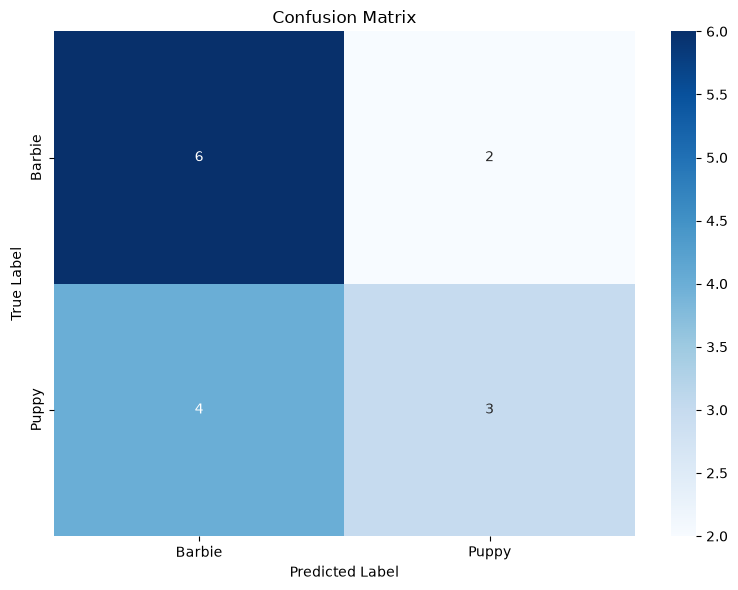

In [12]:
print("ОБУЧЕНИЕ С LOGMEL СПЕКТРОГРАММАМИ")

train_dataset = AugmentedAudioDataset(
    train_files.tolist(), 
    train_labels.tolist(),
    feature_type='logmel',
    augmentation=augmentation_pipeline,
    augment_multiplier=AUGMENTATION_MULTIPLIER
)

val_dataset = AugmentedAudioDataset(
    val_files.tolist(),
    val_labels.tolist(),
    feature_type='logmel',
    augmentation=None,
    augment_multiplier=1
)

test_dataset = AugmentedAudioDataset(
    test_files.tolist(),
    test_labels.tolist(),
    feature_type='logmel',
    augmentation=None,
    augment_multiplier=1
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model_logmel = ImprovedAudioCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_logmel.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5
)

model_logmel, history_logmel = train_model_improved(
    model_logmel, train_loader, val_loader, criterion, optimizer, 
    scheduler, num_epochs=EPOCHS, patience=15
)

print("РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (LogMel)")
test_acc_logmel, test_f1_logmel = evaluate_model(model_logmel, test_loader)

## Обучение с MFCC+Delta

ОБУЧЕНИЕ С MFCC+DELTA


Epoch 1/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 1/100 [Train]:   3%|▎         | 1/35 [00:00<00:28,  1.18it/s]

Epoch 1/100 [Train]:   6%|▌         | 2/35 [00:01<00:24,  1.34it/s]

Epoch 1/100 [Train]:   9%|▊         | 3/35 [00:02<00:23,  1.36it/s]

Epoch 1/100 [Train]:  11%|█▏        | 4/35 [00:03<00:23,  1.35it/s]

... (903 outputs left out)

Epoch 24/100 [Train]:  97%|█████████▋| 34/35 [00:28<00:00,  1.04it/s]

Epoch 24/100 [Train]: 100%|██████████| 35/35 [00:29<00:00,  1.12it/s]

Epoch 24/100 [Train]: 100%|██████████| 35/35 [00:29<00:00,  1.18it/s]

Epoch 24/100
Train Loss: 0.6009, Train Acc: 0.6732
Val Loss: 0.5345, Val Acc: 0.7692
LR: 0.000100
------------------------------------------------------------
Patience: 15/15

Early stopping на эпохе 24
РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (MFCC+Delta)

Test Accuracy: 0.6000
Test F1-Score: 0.5889

Classification Report:
              precision    recall  f1-score   support

      Barbie       0.60      0.75      0.67         8
       Puppy       0.60      0.43      0.50         7

    accuracy                           0.60        15
   macro avg       0.60      0.59      0.58        15
weighted avg       0.60      0.60      0.59        15



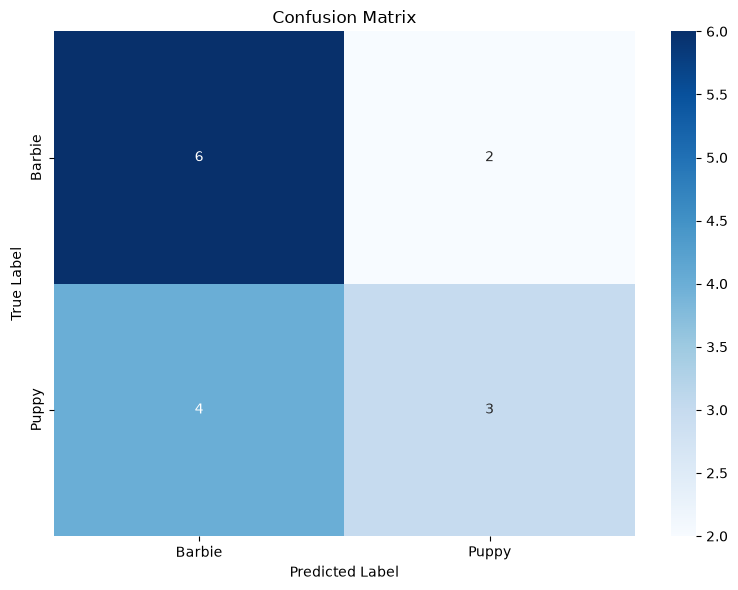

In [13]:
print("ОБУЧЕНИЕ С MFCC+DELTA")

train_dataset_mfcc = AugmentedAudioDataset(
    train_files.tolist(), 
    train_labels.tolist(),
    feature_type='mfcc_delta',
    augmentation=augmentation_pipeline,
    augment_multiplier=AUGMENTATION_MULTIPLIER
)

val_dataset_mfcc = AugmentedAudioDataset(
    val_files.tolist(),
    val_labels.tolist(),
    feature_type='mfcc_delta',
    augmentation=None,
    augment_multiplier=1
)

test_dataset_mfcc = AugmentedAudioDataset(
    test_files.tolist(),
    test_labels.tolist(),
    feature_type='mfcc_delta',
    augmentation=None,
    augment_multiplier=1
)

train_loader_mfcc = DataLoader(train_dataset_mfcc, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader_mfcc = DataLoader(val_dataset_mfcc, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_mfcc = DataLoader(test_dataset_mfcc, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model_mfcc = ImprovedAudioCNN().to(device)

criterion_mfcc = nn.CrossEntropyLoss()
optimizer_mfcc = optim.Adam(model_mfcc.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler_mfcc = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mfcc, mode='min', factor=0.5, patience=5
)

model_mfcc, history_mfcc = train_model_improved(
    model_mfcc, train_loader_mfcc, val_loader_mfcc, criterion_mfcc, 
    optimizer_mfcc, scheduler_mfcc, num_epochs=EPOCHS, patience=15
)

print("РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (MFCC+Delta)")
test_acc_mfcc, test_f1_mfcc = evaluate_model(model_mfcc, test_loader_mfcc)

## Визуализация обучения

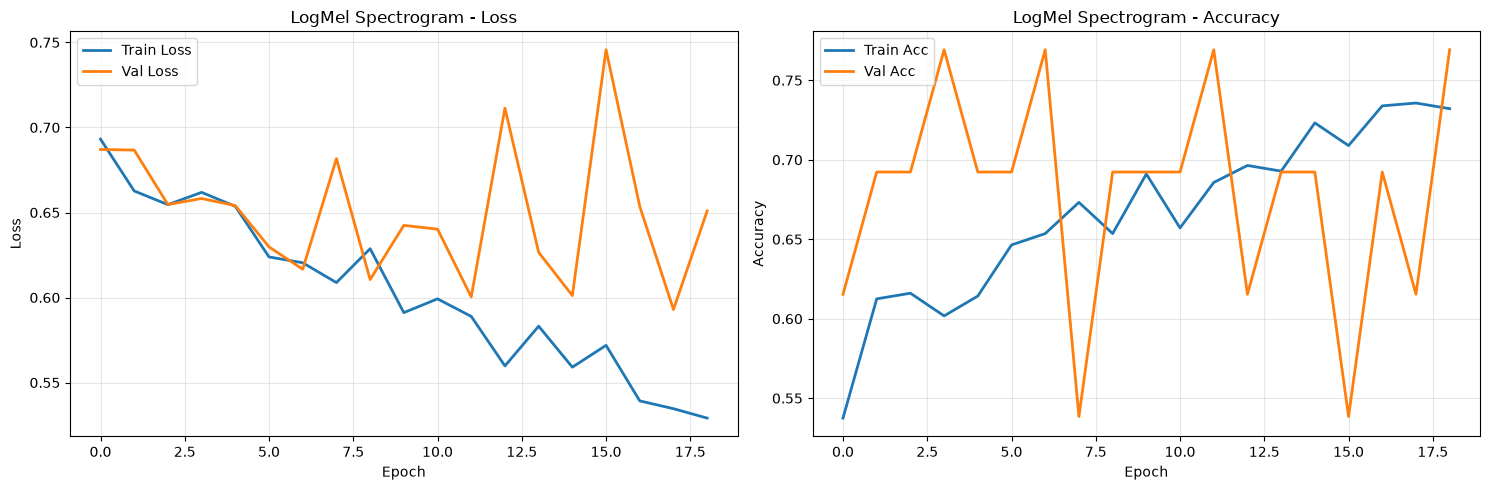

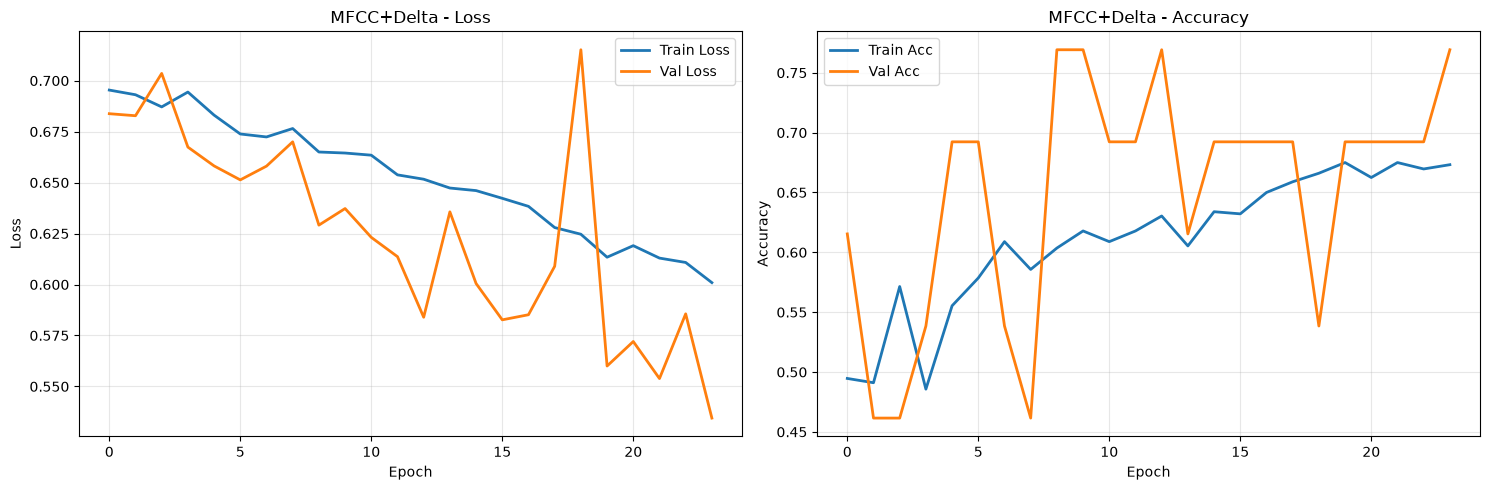

In [14]:
def plot_training_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Loss
    axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2)
    axes[0].plot(history['val_loss'], label='Val Loss', linewidth=2)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{title} - Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Accuracy
    axes[1].plot(history['train_acc'], label='Train Acc', linewidth=2)
    axes[1].plot(history['val_acc'], label='Val Acc', linewidth=2)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{title} - Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Визуализация
plot_training_history(history_logmel, 'LogMel Spectrogram')
plot_training_history(history_mfcc, 'MFCC+Delta')

## Сравнение результатов

            Method  Test Accuracy  Test F1-Score
LogMel Spectrogram            0.6       0.588889
        MFCC+Delta            0.6       0.588889


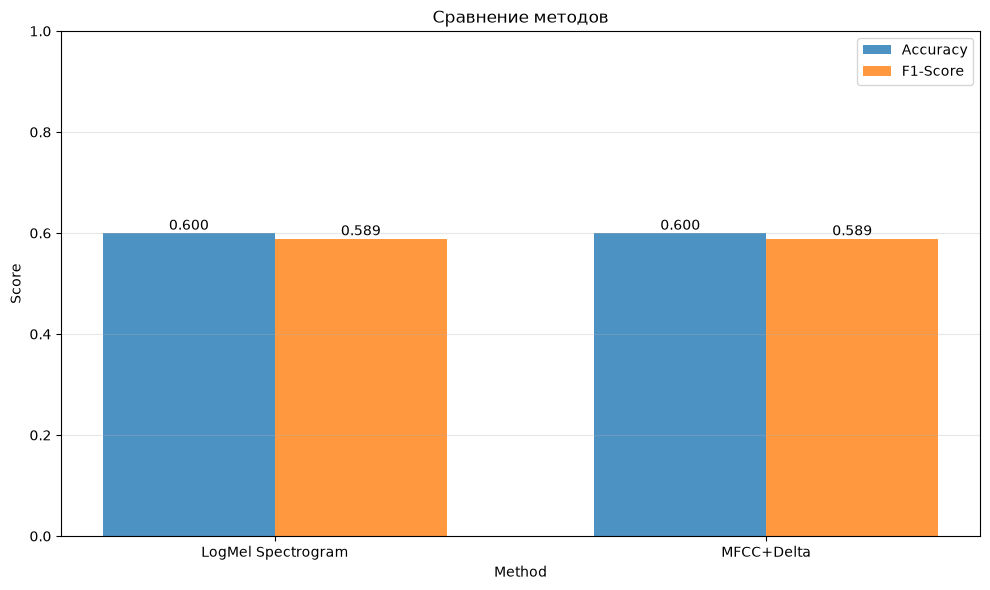

In [15]:
results_summary = pd.DataFrame({
    'Method': ['LogMel Spectrogram', 'MFCC+Delta'],
    'Test Accuracy': [test_acc_logmel, test_acc_mfcc],
    'Test F1-Score': [test_f1_logmel, test_f1_mfcc]
})

print(results_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(results_summary))
width = 0.35

bars1 = ax.bar(x - width/2, results_summary['Test Accuracy'], width, label='Accuracy', alpha=0.8)
bars2 = ax.bar(x + width/2, results_summary['Test F1-Score'], width, label='F1-Score', alpha=0.8)

ax.set_xlabel('Method')
ax.set_ylabel('Score')
ax.set_title('Сравнение методов')
ax.set_xticks(x)
ax.set_xticklabels(results_summary['Method'])
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim([0, 1])

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()